In [92]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import seaborn as sns
import matplotlib.pyplot as plt

In [106]:
labeled = pd.read_csv("/Users/ferolahima/Desktop/gazepoint_project/notebooks/outputs/fixations_on_off_simple.csv")
labeled_blocks = pd.read_csv("/Users/ferolahima/Desktop/gazepoint_project/notebooks/outputs/labeled_with_blocks.csv")
tasks_all = pd.read_csv("/Users/ferolahima/Desktop/gazepoint_project/all_tasks.csv")

/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_74887/1267162338.py:1: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  labeled = pd.read_csv("/Users/ferolahima/Desktop/gazepoint_project/notebooks/outputs/fixations_on_off_simple.csv")
/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_74887/1267162338.py:2: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  labeled_blocks = pd.read_csv("/Users/ferolahima/Desktop/gazepoint_project/notebooks/outputs/labeled_with_blocks.csv")


this is called feature engineering. takes dataframe and break into 3 seconds windows (why??). 

	1.	Group by context
	2.	Split into windows
    3.	Feature extraction per window
    

In [107]:
def extract_features(df, win_size=3.0, time_col="TIME"):
    """
    Aggregate features into ~3s windows, grouped by participant, task, and label (ON/OFF).
    """
    feats = []
    gkeys = ["Video Name (folder)", "User ID (file)", "Task Id", "type", "label"]

    for (vn, uid, tid, ttype, lab), grp in df.groupby(gkeys):
        if grp.empty: 
            continue

        # Split into ~3s chunks
        t_min, t_max = grp[time_col].min(), grp[time_col].max()
        bins = np.arange(t_min, t_max+win_size, win_size)

        grp["window"] = pd.cut(grp[time_col], bins=bins, labels=False)

        for w, wgrp in grp.groupby("window"):
            if wgrp.empty: continue

            feats.append({
                "Video Name (folder)": vn,
                "User ID (file)": uid,
                "Task Id": tid,
                "type": ttype,
                "label": lab,
                "window": int(w),

                # Fixation metrics
                "fixation_count": wgrp["FPOGID"].nunique(),
                "mean_fix_dur": wgrp["FPOGD"].mean(),

                # AOI ratio
                "aoi_ratio": (wgrp["AOI"].notna().sum()) / len(wgrp),

                # Pupil metrics
                "mean_pupil_L": wgrp["LPMM"].mean(),
                "mean_pupil_R": wgrp["RPMM"].mean(),
                "var_pupil_L": wgrp["LPMM"].var(),
                "var_pupil_R": wgrp["RPMM"].var(),

                # Saccade metrics
                "mean_saccade_mag": wgrp["SACCADE_MAG"].mean(),
                "var_saccade_dir": wgrp["SACCADE_DIR"].var(),

                # Blink proxy
                "invalid_samples": (wgrp["FPOGV"]==0).sum()
            })
    return pd.DataFrame(feats)

features = extract_features(labeled)  # your labeled df
features.to_csv("outputs/features_windows.csv", index=False)

“Variance-based features sometimes produced missing values in windows with very few samples (e.g., only one valid pupil measurement). We replaced these missing values with zeros, interpreting them as ‘no measurable variance’.”

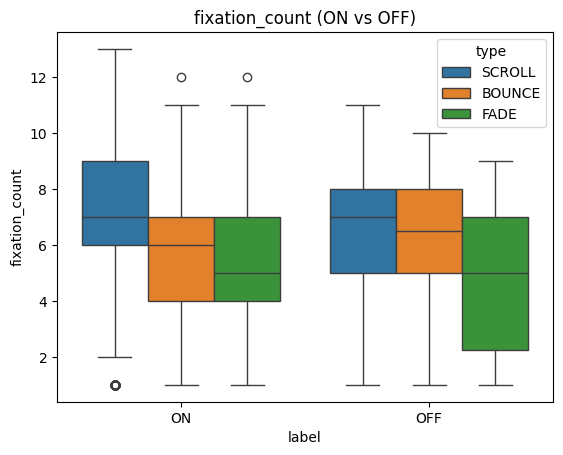

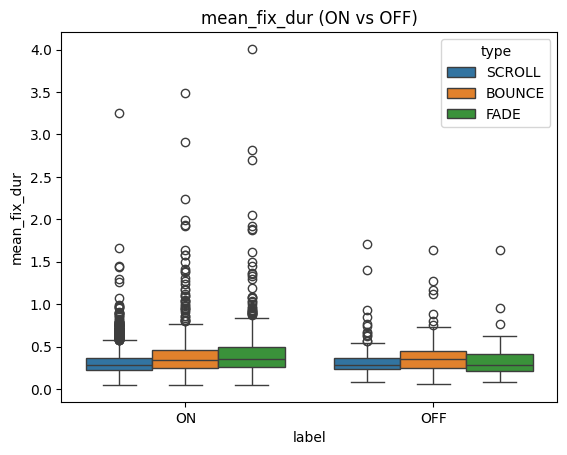

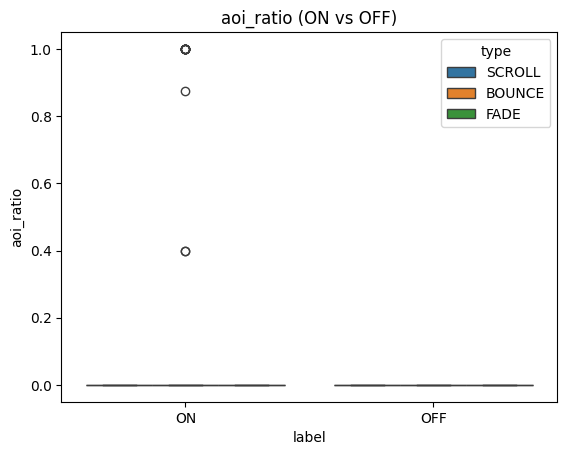

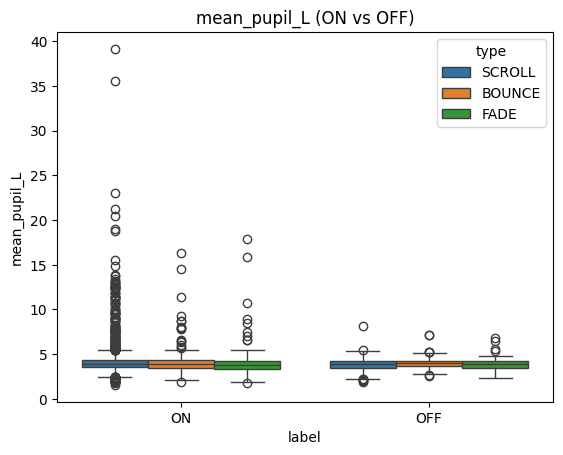

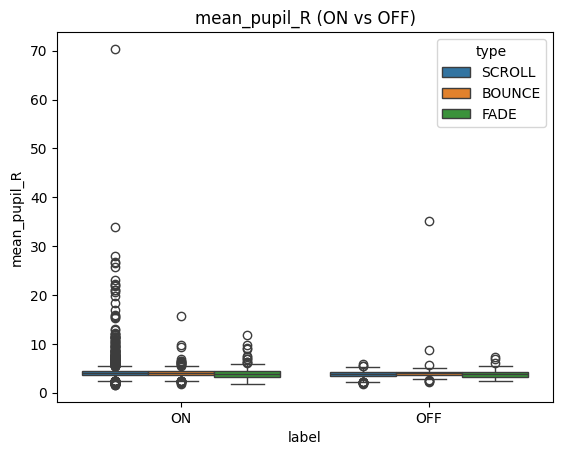

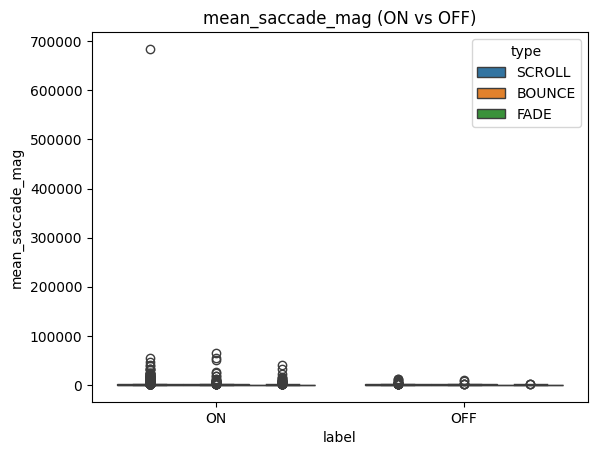

In [105]:
for f in ["fixation_count","mean_fix_dur","aoi_ratio",
          "mean_pupil_L","mean_pupil_R",
          "mean_saccade_mag"]:
    sns.boxplot(x="label", y=f, hue="type", data=features)
    plt.title(f"{f} (ON vs OFF)")
    plt.show()

In [78]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

# numeric features you extracted
feature_cols = [
    "fixation_count","mean_fix_dur","aoi_ratio",
    "mean_pupil_L","mean_pupil_R",
    "var_pupil_L","var_pupil_R",
    "mean_saccade_mag","var_saccade_dir","invalid_samples"
]

# take only those columns
X = features[feature_cols].copy()   # or use deltas[feature_cols]

# handle missing values
X = X.fillna(0)  # interpret NaN as "no variance" or "no data"

# scale all features (important for PCA/clustering)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# keep labels/metadata for plotting later
labels = features["label"].values   # ON/OFF
types  = features["type"].values    # FADE/SCROLL/BOUNCE

Explained variance ratio: [0.21198846 0.1490956 ]


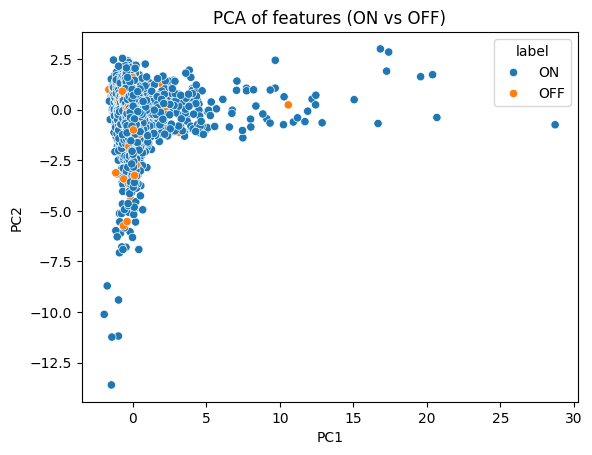

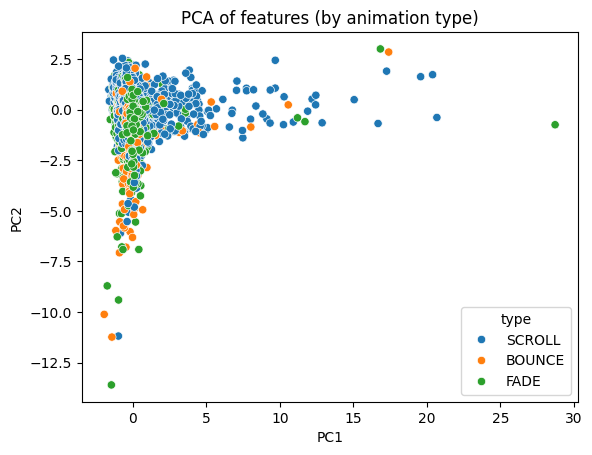

In [79]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# run PCA
pca = PCA(n_components=2)
pcs = pca.fit_transform(X_scaled)

# make DataFrame with PCs and labels
pca_df = pd.DataFrame(pcs, columns=["PC1","PC2"])
pca_df["label"] = labels
pca_df["type"]  = types

print("Explained variance ratio:", pca.explained_variance_ratio_)

# plot ON vs OFF
sns.scatterplot(x="PC1", y="PC2", hue="label", data=pca_df)
plt.title("PCA of features (ON vs OFF)")
plt.show()

# plot by animation type
sns.scatterplot(x="PC1", y="PC2", hue="type", data=pca_df)
plt.title("PCA of features (by animation type)")
plt.show()

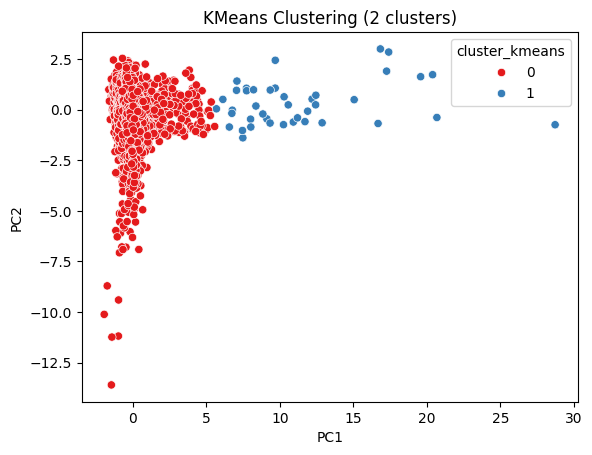

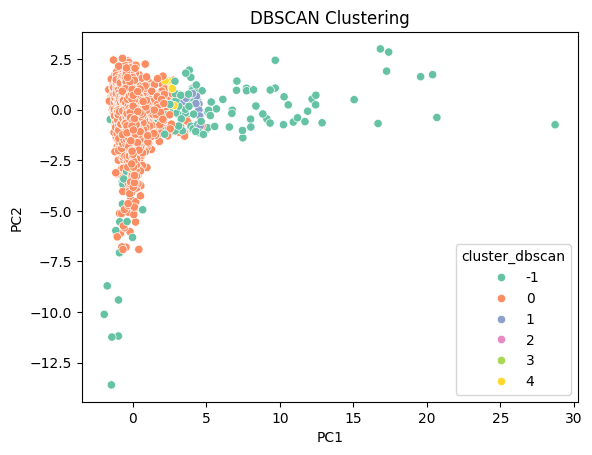

In [80]:
from sklearn.cluster import KMeans, DBSCAN

# --- KMeans with 2 clusters
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
pca_df["cluster_kmeans"] = kmeans.fit_predict(X_scaled)

sns.scatterplot(x="PC1", y="PC2", hue="cluster_kmeans", data=pca_df, palette="Set1")
plt.title("KMeans Clustering (2 clusters)")
plt.show()

# --- DBSCAN (density-based, can detect outliers)
db = DBSCAN(eps=1.5, min_samples=5).fit(X_scaled)
pca_df["cluster_dbscan"] = db.labels_

sns.scatterplot(x="PC1", y="PC2", hue="cluster_dbscan", data=pca_df, palette="Set2")
plt.title("DBSCAN Clustering")
plt.show()

In [ ]:
# jo koment jo